# Axo: offline analysis and next-condition recommendation

Run **all cells** after installing the pinned environment described in `README_offline.md`.
This notebook uses the archived BO round 4 batch, including the original CSV files,
recipes and operation log. It makes no hardware connection and executes no synthesis.

The example demonstrates one computation cycle. Its GP uses this batch only,
so its proposals are not presented as the historical next BO batch or as a replay
of the full optimization campaign. The objective is explicitly **k_n = 1/a**;
`I_max` remains the fitted optical amplitude, not the optimization objective.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from science_jubilee.offline_demo import default_data_dir, run_demo, verify_input_files

DATA_DIR = default_data_dir()
OUTPUT_DIR = Path.cwd() / "offline_demo_outputs"
SEED = 42
THRESHOLD = 0.5
provenance = verify_input_files(DATA_DIR)
print("Source batch:", provenance["source_batch"])
print("Source commit:", provenance["commit"])
print("Verified input files:", len(provenance["files"]))
print("Output directory relative to the notebook location:", OUTPUT_DIR.name)

Source batch: Dataset/BO_4_Zuyang_20251117_190856
Source commit: 01278f84fd592dd0afdffaeec1bd71f6105af90e
Verified input files: 8
Output directory relative to the notebook location: offline_demo_outputs


## Run the recorded-data workflow

The deposited closest-two replicate averaging, Gualtieri fitting and GP/EI
functions are reused. Optical gates follow `gualtieri.ipynb`. Actual elapsed
times are calculated from the operation log, relative to each baseline visit.
The normalized optical trajectory uses the fitted amplitude without clipping.

An optical gate failure receives a zero **optimization score**, not a measured
zero nucleation rate. Unexpected fitting or missing-log errors stop the demo.

In [2]:
summary = run_demo(DATA_DIR, OUTPUT_DIR, seed=SEED, threshold=THRESHOLD, progress=False)
print("Run time (s):", round(summary["elapsed_seconds"], 2))
display(pd.Series(summary["package_versions"], name="Version"))

Run time (s): 17.21


axo-mof            0.1.0
numpy              2.3.5
scipy             1.17.0
pandas             2.2.3
scikit-learn       1.8.0
matplotlib        3.10.8
python-ternary     1.0.8
Name: Version, dtype: object

## Inspect the fitted descriptors

Bounds and optimizer warnings are retained in the output. A high R² alone does
not establish precise parameter identification. Optical screening is not an
independent structural characterization.

,vial_id,status,a_min,k_n_min_inverse,R2,alpha_first_followup,parameter_at_bound,a_outside_observed_window
0,B1,fitted,8.447894,0.118373,0.998093,0.648289,False,False
1,B2,no_target_feature,NaN,NaN,NaN,NaN,False,False
2,B3,fitted,15049.574465,0.000066,0.999093,0.010816,False,True
3,B4,no_reaction,NaN,NaN,NaN,NaN,False,False
4,B5,fitted,22.970915,0.043533,0.998479,0.226529,False,False


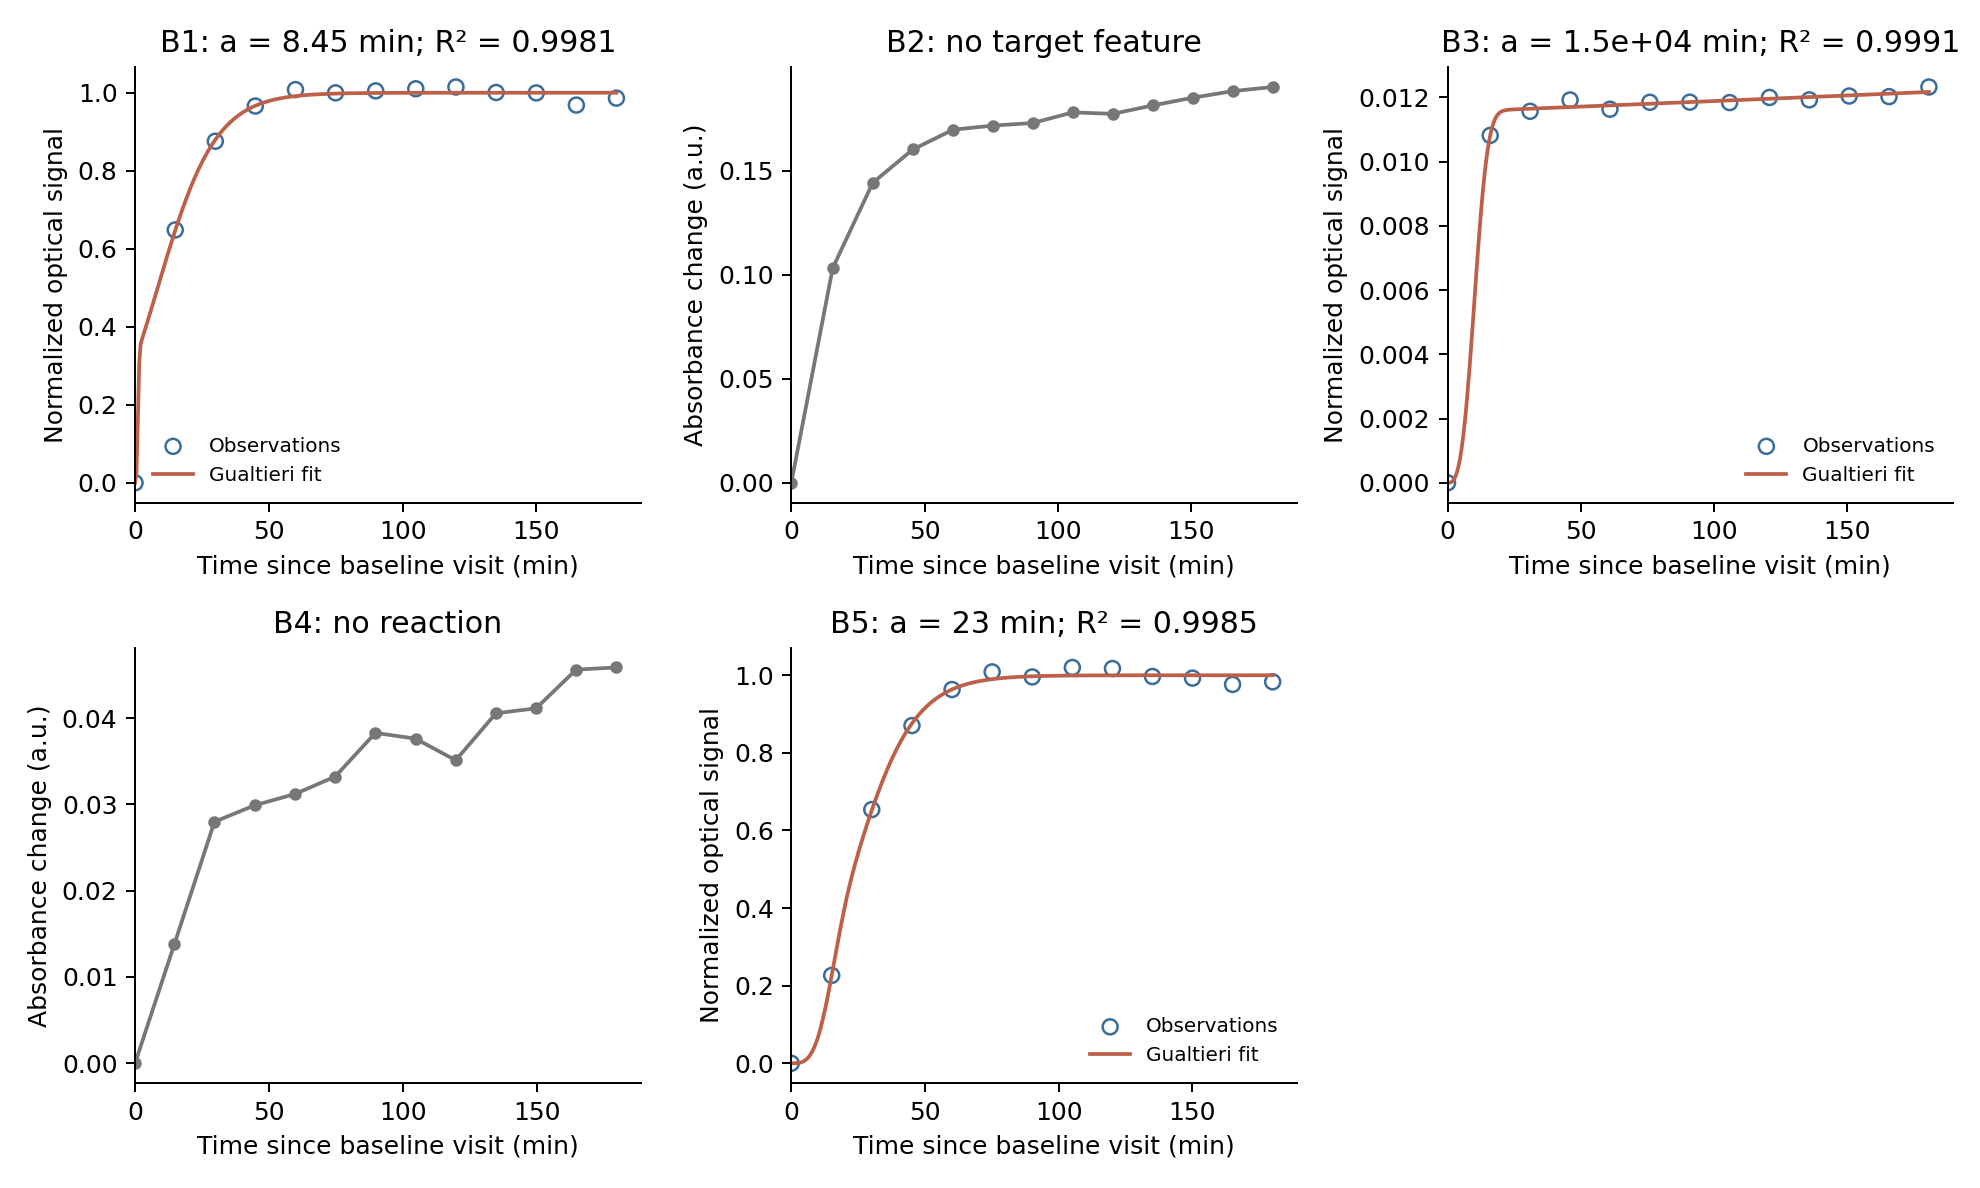

In [3]:
parameters = pd.read_csv(OUTPUT_DIR / "kinetic_parameters.csv")
display(parameters[["vial_id", "status", "a_min", "k_n_min_inverse", "R2",
                    "alpha_first_followup", "parameter_at_bound", "a_outside_observed_window"]])
display(Image(filename=str(OUTPUT_DIR / "kinetic_fits.png")))

## Inspect the proposed schedule and formulations

The strict `max(alpha_first_followup) > 0.5` rule is applied only to fitted
trajectories. Proposed conditions are saved to files; no robot-ready command
is sent and `executed` is always false.

threshold                                                0.5
max_alpha_first_followup                            0.648289
switch_to_measurement_prioritized                       True
next_mode                            measurement-prioritized
next_batch_size                                            2
next_measurement_interval_min                              5
executed                                               False
Name: Decision, dtype: object

,proposal_rank,Co_mL,mIm_mL,TEA_mL,predicted_score,predictive_std,expected_improvement
0,1,5.0,0.1,2.9,0.104296,0.029321,0.003395
1,2,3.8,1.2,3.0,0.110437,0.023584,0.003038


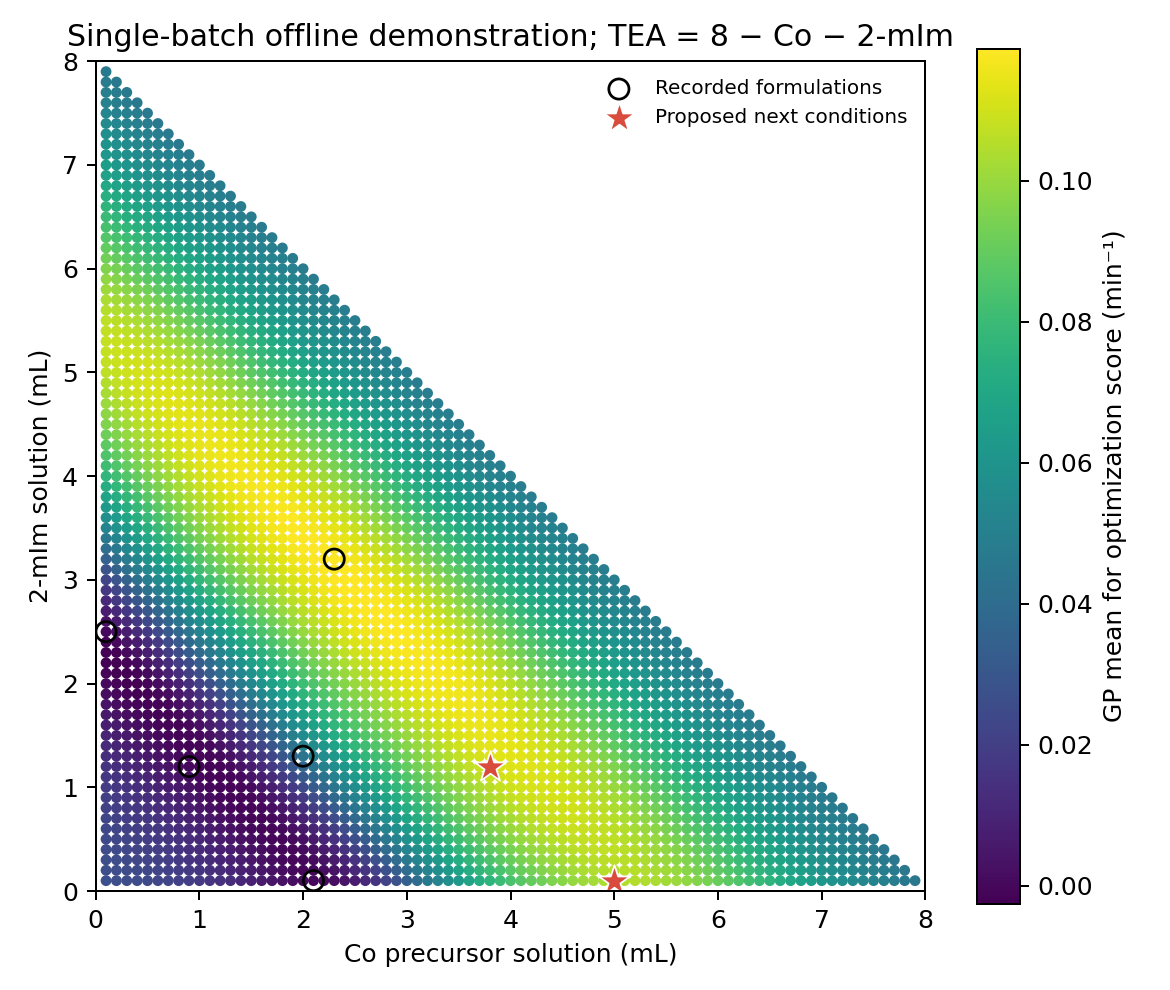

In [4]:
plan = json.loads((OUTPUT_DIR / "next_batch_plan.json").read_text())
display(pd.Series({k: v for k, v in plan.items() if k != "proposals"}, name="Decision"))
display(pd.read_csv(OUTPUT_DIR / "next_conditions.csv"))
display(Image(filename=str(OUTPUT_DIR / "gp_recommendations.png")))

## Check the numerical outputs

These checks concern this recorded-data software demonstration. They do not
test physical robotic repeatability or isolate the scientific benefit of adaptive
execution. The separate `tests/` scripts verify reference values and exercise
the complete workflow with network connections and hardware imports blocked.

In [5]:
import numpy as np
proposals = pd.read_csv(OUTPUT_DIR / "next_conditions.csv")
volumes = proposals[["Co_mL", "mIm_mL", "TEA_mL"]].to_numpy()
assert np.allclose(volumes.sum(axis=1), 8.0)
assert (volumes >= 0).all()
assert len(proposals) == plan["next_batch_size"]
assert not plan["executed"]
assert summary["input_hashes_verified"]
assert set(parameters["vial_id"]) == {"B1", "B2", "B3", "B4", "B5"}
print("Input integrity, composition constraints and proposal-only execution checks passed.")
print("Warnings retained in run_summary.json:")
for warning in summary["warnings"]:
    print("-", warning)

Input integrity, composition constraints and proposal-only execution checks passed.
Warnings retained in run_summary.json:
- B3: Fitted a exceeds the observed time window; this is an extrapolated model parameter, not a directly resolved nucleation time.
- GP: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 1.0. Increasing the bound and calling fit again may find a better value.
- GP: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
- GP: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 1.0. Increasing the bound and calling fit again may find a better value.
